# Estimasi Premi Risiko Tahunan Asuransi Kendaraan
**Portfolio Jasen Theodorus · freMTPL2 · End-to-end machine learning**

Notebook ini mengestimasi ekspektasi biaya klaim per satu tahun pertanggungan, bukan premi komersial atau jaminan kecukupan modal. Cakupan data: motor third-party liability Prancis; tidak langsung berlaku untuk comprehensive Indonesia.

Alur: audit → rekonsiliasi → split → EDA train → preprocessing → tuning & seleksi validation → refit → evaluasi test → interpretasi → simulasi → rekomendasi → ekspor.

**Menjalankan:** letakkan pasangan `freMTPL2freq` dan `freMTPL2sev` (CSV atau ARFF asli) bersama notebook, buka di VS Code/Jupyter, pilih kernel Python, lalu Run All. Tidak membutuhkan API key. Output tersimpan di folder `outputs_motor_pricing`. Data tidak dibundel dalam notebook. Loader mendukung ARFF asli tanpa konversi; jika kedua format tersedia, ARFF diprioritaskan. Output bawaan diuji pada ARFF asli lengkap (678.013 polis). Default menggunakan seluruh data; `MAX_POLICIES` dapat diisi 100000 untuk percobaan awal. Jalankan kembali dengan `None` untuk laporan final.

**Instalasi satu kali jika diperlukan:** jalankan `%pip install "pandas>=2.2,<4" "numpy>=1.26,<3" "scikit-learn>=1.4,<2" "matplotlib>=3.8,<4" "joblib>=1.3" threadpoolctl ipykernel` pada sel baru. Restart kernel setelah instalasi. Output bawaan notebook merekam lingkungan pengujian; hasil dapat berbeda sedikit antarversi.

In [1]:
from pathlib import Path
import json, sys, platform, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import PoissonRegressor, GammaRegressor, TweedieRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_tweedie_deviance, mean_poisson_deviance, mean_gamma_deviance, mean_absolute_error, mean_squared_error
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
SEED = 42
DATA_DIR = Path("..")
OUT = DATA_DIR / "outputs_motor_pricing"
OUT.mkdir(exist_ok=True)
MAX_POLICIES = None
POWER = 1.5  # satu power evaluasi yang sama untuk semua kandidat
EPS = 1e-9
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_columns', 20)
versions = {'python':platform.python_version(), 'numpy':np.__version__, 'pandas':pd.__version__, 'sklearn':sklearn.__version__, 'joblib':joblib.__version__}
print(versions)

{'python': '3.12.10', 'numpy': '2.3.5', 'pandas': '2.2.3', 'sklearn': '1.8.0', 'joblib': '1.5.3'}


In [2]:
from pathlib import Path
print("Lokasi kerja:", Path.cwd())

Lokasi kerja: c:\Users\Lenovo\OneDrive\Documents\Dibimbing\Data Science\Assignment\Final Project\notebook


In [3]:
from pathlib import Path

root = Path("..")

for file in [
    root / "data/raw/freMTPL2freq.csv",
    root / "data/raw/freMTPL2sev.csv",
    root / "models/motor_pricing.joblib",
]:
    print(f"{file.name}: {'✅ Ditemukan' if file.is_file() else '❌ Belum ditemukan'}")

freMTPL2freq.csv: ✅ Ditemukan
freMTPL2sev.csv: ✅ Ditemukan
motor_pricing.joblib: ✅ Ditemukan


In [4]:
required = [
    "final_models",
    "winner",
    "final_rate",
    "freq_best",
    "sev_best",
    "direct_best",
    "FEATURES",
    "versions",
    "test_scores",
]

missing = [name for name in required if name not in globals()]

if missing:
    print("Variabel training belum tersedia:", missing)
else:
    print("Hasil training tersedia. Bisa menjalankan bagian ekspor.")

Variabel training belum tersedia: ['final_models', 'winner', 'final_rate', 'freq_best', 'sev_best', 'direct_best', 'FEATURES', 'test_scores']


## 1. Business understanding dan data dictionary
Premi risiko = estimasi frekuensi tahunan × estimasi biaya per klaim, dengan asumsi struktur frequency–severity sesuai. Alternatif: langsung memodelkan total biaya / exposure menggunakan Tweedie.

|Kolom|Definisi|Peran|
|---|---|---|
|IDpol|Identitas polis|Join dan pemisahan; bukan fitur|
|ClaimNb|Jumlah klaim selama exposure|Target frequency|
|Exposure|Lama pertanggungan dalam tahun|Bobot/normalisasi target|
|Area|Kode kepadatan A (rural) hingga F (urban centre)|Fitur kategori|
|VehPower|Tingkat tenaga kendaraan|Fitur numerik berurutan|
|VehAge|Usia kendaraan, tahun|Fitur numerik|
|DrivAge|Usia pengemudi, tahun|Fitur numerik|
|BonusMalus|Indeks bonus–malus; <100 bonus, >100 malus|Fitur hanya jika tersedia sebelum periode prediksi|
|VehBrand|Kode merek yang disamarkan|Fitur kategori|
|VehGas|Diesel/Regular|Fitur kategori|
|Density|Penduduk/km²|Fitur numerik, log1p|
|Region|Kode wilayah Prancis|Fitur kategori|
|ClaimAmount|Biaya satu catatan klaim, EUR menurut referensi benchmark|Target severity|

`ClaimNb`, `ClaimAmount`, dan target turunan tidak digunakan sebagai fitur. Tidak ada harga premi komersial atau tahun kalender per baris untuk menguji loss ratio komersial atau temporal split.

In [5]:
def load_table(stem):
    # ARFF diprioritaskan; cari juga data/raw dan upload untuk penggunaan lokal.
    folders=[DATA_DIR,DATA_DIR/'data'/'raw',DATA_DIR/'upload']
    options=[folder/f'{stem}{ext}' for ext in ['.arff','.csv'] for folder in folders]
    path=next((p for p in options if p.exists()),None)
    if path is None: raise FileNotFoundError(f'Taruh {stem}.csv atau {stem}.arff di {DATA_DIR.resolve()}')
    if path.suffix=='.arff':
        names=[]
        with path.open(encoding='utf-8-sig') as f:
            for i,line in enumerate(f):
                if line.lower().startswith('@attribute'): names.append(line.split()[1])
                if line.strip().lower()=='@data': break
            else: raise ValueError('ARFF tidak memiliki bagian @data')
        df=pd.read_csv(path,skiprows=i+1,names=names,quotechar="'",na_values=['?'],dtype={'IDpol':'string'})
    else:
        df=pd.read_csv(path,dtype={'IDpol':'string'})
    print('Loaded:',path,'shape:',df.shape)
    return df
freq_raw=load_table('freMTPL2freq')
sev_raw=load_table('freMTPL2sev')
if len(freq_raw)!=678013 or len(sev_raw)!=26639:
    warnings.warn('Jumlah baris berbeda dari file OpenML awal (678013/26639). Periksa kelengkapan file/versi sebelum menafsirkan hasil.')
display(freq_raw.head()); display(sev_raw.head())
display(pd.DataFrame({'dtype':freq_raw.dtypes.astype(str),'missing':freq_raw.isna().sum(),'unique':freq_raw.nunique()}))

Loaded: ..\data\raw\freMTPL2freq.csv shape: (678013, 12)
Loaded: ..\data\raw\freMTPL2sev.csv shape: (26639, 2)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1,1,0.10,D,5,0,55,50,B12,Regular,1217,R82
1,3,1,0.77,D,5,0,55,50,B12,Regular,1217,R82
2,5,1,0.75,B,6,2,52,50,B12,Diesel,54,R22
3,10,1,0.09,B,7,0,46,50,B12,Diesel,76,R72
4,11,1,0.84,B,7,0,46,50,B12,Diesel,76,R72


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


,dtype,missing,unique
IDpol,string,0,678013
ClaimNb,int64,0,11
Exposure,float64,0,181
Area,object,0,6
VehPower,int64,0,12
VehAge,int64,0,78
DrivAge,int64,0,83
BonusMalus,int64,0,115
VehBrand,object,0,11
VehGas,object,0,2


## 2. Data cleaning dan audit
Aturan berbasis validitas, bukan hasil test: ID wajib terisi; exposure harus positif; jumlah klaim harus bilangan bulat nonnegatif; biaya klaim harus positif. Duplikasi ID frequency menghentikan proses agar tidak menghapus kontrak secara sembarang. Baris severity yang identik tetap dipertahankan: klaim berbeda dapat bernilai sama dan tidak ada claim ID.

Exposure >1 dan klaim ekstrem **dipertahankan**. Tidak ada winsorization otomatis: memangkas klaim mengubah target risiko. Nilai fitur yang tidak masuk akal dijadikan missing dan diimputasi dari train.

In [6]:
freq, sev = freq_raw.copy(), sev_raw.copy()
CAT = ['Area','VehBrand','VehGas','Region']
RAW_NUM = ['VehPower','VehAge','DrivAge','BonusMalus','Density']
assert set(['IDpol','ClaimNb','Exposure']+CAT+RAW_NUM).issubset(freq.columns)
assert {'IDpol','ClaimAmount'}.issubset(sev.columns)
for df in [freq,sev]:
    df['IDpol'] = df.IDpol.str.strip().str.replace(r'\.0$','',regex=True)
    df.loc[df.IDpol.eq(''), 'IDpol'] = pd.NA
for c in RAW_NUM+['ClaimNb','Exposure']:
    freq[c] = pd.to_numeric(freq[c],errors='coerce').replace([np.inf,-np.inf],np.nan)
sev['ClaimAmount'] = pd.to_numeric(sev.ClaimAmount,errors='coerce').replace([np.inf,-np.inf],np.nan)
for c in CAT:
    freq[c] = freq[c].astype('string').str.strip().str.strip("'")
    freq[c] = freq[c].replace({'':pd.NA,'?':pd.NA}).astype(object)
    freq[c] = freq[c].where(pd.notna(freq[c]),np.nan)
valid_freq = (freq.IDpol.notna() & freq.Exposure.gt(0) & freq.ClaimNb.ge(0) & freq.ClaimNb.mod(1).eq(0))
valid_sev = sev.IDpol.notna() & sev.ClaimAmount.gt(0)
freq.loc[~valid_freq].to_csv(OUT/'quarantine_frequency.csv',index=False)
sev.loc[~valid_sev].to_csv(OUT/'quarantine_severity.csv',index=False)
bad_sev_ids = set(sev.loc[~valid_sev,'IDpol'].dropna())
freq = freq.loc[valid_freq].copy(); sev = sev.loc[valid_sev].copy()
if freq.IDpol.duplicated().any(): raise ValueError('Duplikasi IDpol frequency: investigasi sebelum modeling.')
for c in RAW_NUM:
    freq.loc[freq[c].lt(0),c] = np.nan
freq.loc[freq.DrivAge.lt(18),'DrivAge'] = np.nan
for c in ['VehPower','BonusMalus']:
    freq.loc[freq[c].eq(0),c] = np.nan
print('Baris frequency invalid:',int((~valid_freq).sum()))
print('Baris severity invalid:',int((~valid_sev).sum()))
print('Exposure >1 dipertahankan:',int(freq.Exposure.gt(1).sum()))
print('Baris severity identik (tidak dihapus):',int(sev.duplicated().sum()))
display(sev.ClaimAmount.describe(percentiles=[.5,.9,.99,.999]).to_frame())

Baris frequency invalid: 0
Baris severity invalid: 0
Exposure >1 dipertahankan: 1224
Baris severity identik (tidak dihapus): 255


,ClaimAmount
count,2.663900e+04
mean,2.278536e+03
std,2.929748e+04
min,1.000000e+00
50%,1.172000e+03
90%,2.799072e+03
99%,1.679370e+04
99.9%,1.627844e+05
max,4.075401e+06


## 3. Rekonsiliasi dan definisi populasi pricing
Ketiadaan severity pada polis dengan `ClaimNb > 0` berarti **nilai klaim belum diketahui dalam pasangan file ini**. Tidak diisi nol. Hanya polis tanpa klaim yang tidak memiliki severity diberi total biaya nol.

Model utama menggunakan **cohort rekonsiliasi**: polis tanpa klaim yang konsisten, atau polis ber-klaim dengan jumlah catatan severity sama dengan ClaimNb. Polis bermasalah dikarantina; target tidak diimputasi. Ini keputusan transparan untuk demonstrasi, tetapi dapat menyebabkan selection bias. Hasil tidak boleh diklaim terkalibrasi untuk seluruh portofolio asli. Penyebab ketidakcocokan perlu dikonfirmasi ke sumber sebelum deployment.

In [7]:
orphans = sev.loc[~sev.IDpol.isin(freq.IDpol)].copy()
orphans.to_csv(OUT/'orphan_claims.csv',index=False)
agg = sev.groupby('IDpol',as_index=False).agg(TotalClaimAmount=('ClaimAmount','sum'), SeverityRows=('ClaimAmount','size'))
pol = freq.merge(agg,on='IDpol',how='left',validate='one_to_one')
zero_ok = pol.ClaimNb.eq(0) & pol.SeverityRows.isna()
positive_ok = pol.ClaimNb.gt(0) & pol.SeverityRows.eq(pol.ClaimNb)
pol['Reconciled'] = (zero_ok | positive_ok) & ~pol.IDpol.isin(bad_sev_ids)
pol.loc[zero_ok,'TotalClaimAmount'] = 0.0
pol['Status'] = np.select([pol.IDpol.isin(bad_sev_ids),pol.ClaimNb.gt(0)&pol.SeverityRows.isna(),pol.Reconciled], ['invalid_severity','missing_severity','reconciled'], default='count_mismatch')
audit = pol.groupby('Status').agg(Policies=('IDpol','size'),Exposure=('Exposure','sum'),Claims=('ClaimNb','sum'))
audit['Frequency'] = audit.Claims/audit.Exposure
display(audit); audit.to_csv(OUT/'reconciliation_audit.csv')
print('Orphan severity rows:',len(orphans),'| IDs:',orphans.IDpol.nunique())
pol.loc[~pol.Reconciled].to_csv(OUT/'unreconciled_policies.csv',index=False)
cohort = pol.loc[pol.Reconciled].copy()
cohort['Frequency'] = cohort.ClaimNb/cohort.Exposure
cohort['PurePremium'] = cohort.TotalClaimAmount/cohort.Exposure
cohort['AvgSeverity'] = cohort.TotalClaimAmount/cohort.ClaimNb.replace(0,np.nan)
assert cohort.PurePremium.notna().all()
print('Cohort pricing:',len(cohort),'dari',len(pol),'polis valid')

,Policies,Exposure,Claims,Frequency
Status,,,,
count_mismatch,1,0.820000,2,2.439024
missing_severity,9116,4605.457432,9657,2.096860
reconciled,668896,353893.168031,26443,0.074720


Orphan severity rows: 195 | IDs: 6
Cohort pricing: 668896 dari 678013 polis valid


## 4. Train / validation / test
Split 60/20/20 pada ID polis, stratifikasi ada/tidaknya klaim. Semua klaim suatu polis mengikuti split polis tersebut. ID pemegang polis dan waktu tidak tersedia: korelasi antarkontrak tidak sepenuhnya dapat dikesampingkan. Jangan memakai hasil test untuk memilih hyperparameter. EDA berikut hanya memakai train; pemeriksaan kualitas data sebelumnya menggunakan aturan tetap.

In [8]:
if MAX_POLICIES is not None and len(cohort)>MAX_POLICIES:
    cohort, _ = train_test_split(cohort,train_size=MAX_POLICIES,stratify=cohort.ClaimNb.gt(0),random_state=SEED)
train, temp = train_test_split(cohort,test_size=.4,stratify=cohort.ClaimNb.gt(0),random_state=SEED)
val, test = train_test_split(temp,test_size=.5,stratify=temp.ClaimNb.gt(0),random_state=SEED)
assert set(train.IDpol).isdisjoint(val.IDpol) and set(train.IDpol).isdisjoint(test.IDpol) and set(val.IDpol).isdisjoint(test.IDpol)
display(pd.DataFrame([{'split':n,'policies':len(d),'exposure':d.Exposure.sum(),'claiming_pct':100*d.ClaimNb.gt(0).mean()} for n,d in [('train',train),('validation',val),('test',test)]]))
pd.concat([d[['IDpol']].assign(split=n) for n,d in [('train',train),('validation',val),('test',test)]]).to_csv(OUT/'split_ids.csv',index=False)

,split,policies,exposure,claiming_pct
0,train,401337,212410.933440,3.729036
1,validation,133779,70685.560572,3.728537
2,test,133780,70796.674019,3.729257


## 5. Exploratory data analysis (train)
Frekuensi kelompok dihitung sebagai jumlah klaim / jumlah exposure, bukan rata-rata rasio per polis. Premi murni kelompok = total biaya / total exposure. Grafik log hanya untuk visualisasi; target model tetap skala biaya asli.

,count,mean,std,min,25%,50%,75%,max
VehPower,401337.0,6.458316,2.051800,4.000000,5.00,6.00,7.00,15.00
VehAge,401337.0,7.091135,5.659121,0.000000,2.00,6.00,11.00,100.00
DrivAge,401337.0,45.475506,14.134957,18.000000,34.00,44.00,55.00,100.00
BonusMalus,401337.0,59.754309,15.619517,50.000000,50.00,50.00,64.00,230.00
Density,401337.0,1792.155924,3950.772093,1.000000,93.00,393.00,1662.00,27000.00
Exposure,401337.0,0.529258,0.364062,0.002732,0.18,0.49,0.99,2.01
ClaimNb,401337.0,0.039493,0.207740,0.000000,0.00,0.00,0.00,11.00
TotalClaimAmount,401337.0,94.514148,7292.509724,0.000000,0.00,0.00,0.00,4075400.56


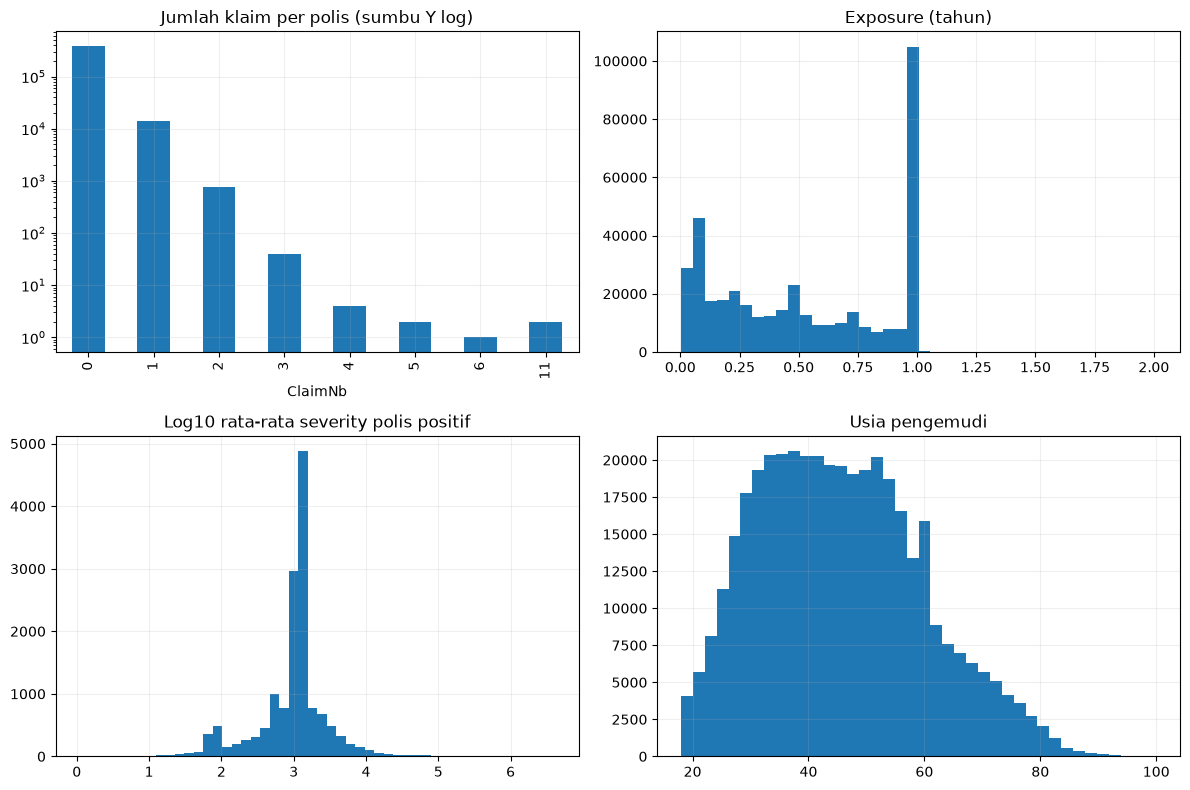

,Policies,Exposure,Claims,Loss,Frequency,Severity,PurePremium
DriverAgeBand,,,,,,,
"(17, 25]",23065,9669.253699,1432,9805117.38,0.148098,6847.149008,1014.051103
"(25, 35]",88525,41255.435835,3137,6464789.71,0.076038,2060.819162,156.701525
"(35, 45]",100915,51998.057414,3744,7028803.24,0.072003,1877.351293,135.174343
"(45, 55]",95708,52749.880827,3979,8057413.79,0.075431,2024.984617,152.747526
"(55, 65]",53666,30658.667486,2019,3398128.13,0.065854,1683.074854,110.837437
"(65, 120]",39458,26079.638180,1539,3177772.18,0.059012,2064.829227,121.848783


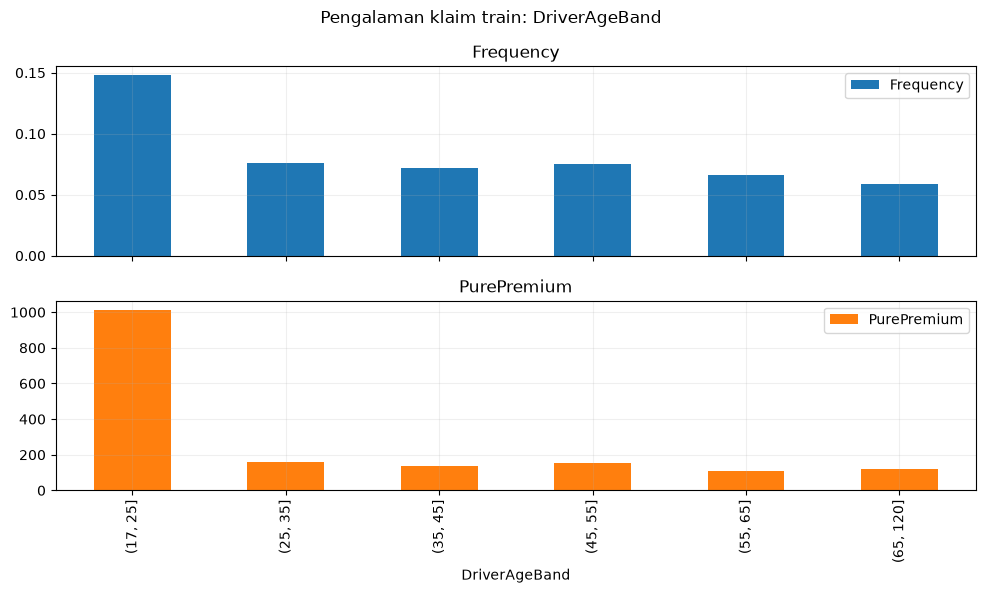

,Policies,Exposure,Claims,Loss,Frequency,Severity,PurePremium
Area,,,,,,,
A,61409,36599.945980,2087,5323128.01,0.057022,2550.612367,145.440871
B,44478,25393.999956,1553,7070851.01,0.061156,4553.027051,278.445736
C,113650,61807.091157,4265,8994280.08,0.069005,2108.858166,145.521815
D,89694,45680.497236,3803,8687761.20,0.083252,2284.449435,190.185347
E,81561,38116.138504,3672,7037794.29,0.096337,1916.610645,184.640800
F,10545,4813.260607,470,818209.84,0.097647,1740.872000,169.990762


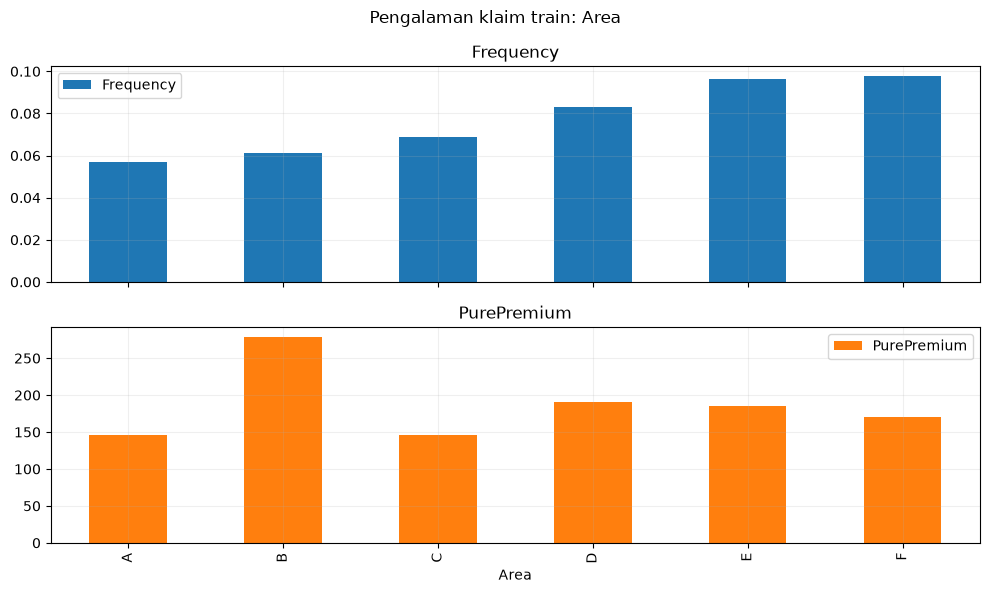

,Policies,Exposure,Claims,Loss,Frequency,Severity,PurePremium
VehGas,,,,,,,
Diesel,197330,101361.675547,8011,16171853.20,0.079034,2018.705929,159.546033
Regular,204007,111049.257894,7839,21760171.23,0.070590,2775.886112,195.950623


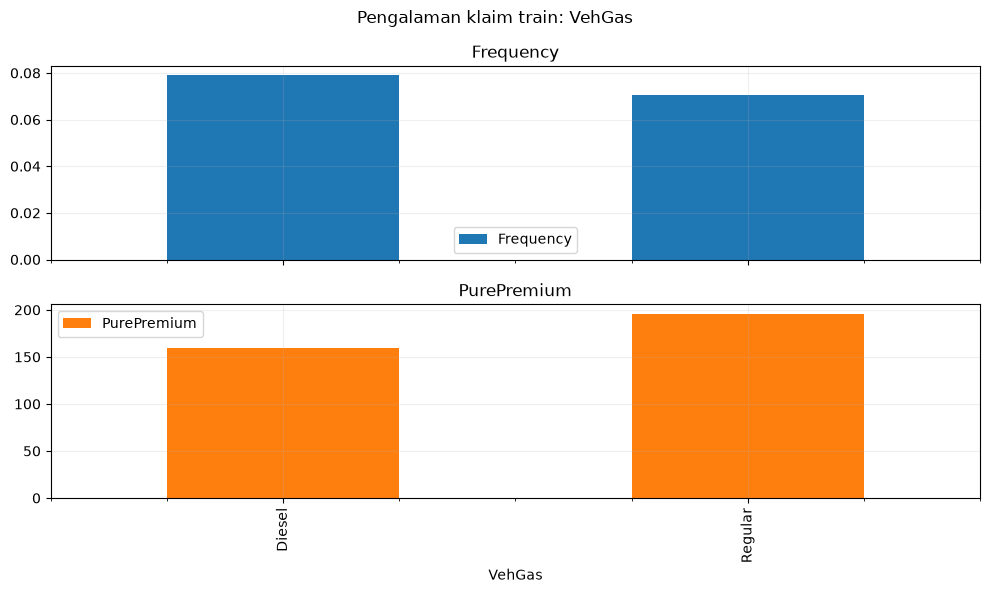

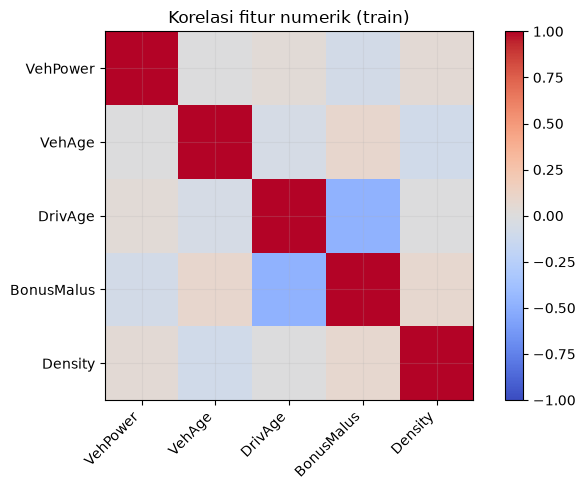

Porsi biaya dari 1% polis positif terbesar: 0.4047
Interpretasi: segmen kecil dan klaim ekstrem dapat membuat rata-rata sangat volatil; hubungan bukan kausalitas.


In [9]:
display(train[RAW_NUM+['Exposure','ClaimNb','TotalClaimAmount']].describe().T)
fig, axes = plt.subplots(2,2,figsize=(12,8))
train.ClaimNb.value_counts().sort_index().plot.bar(ax=axes[0,0],logy=True,title='Jumlah klaim per polis (sumbu Y log)')
train.Exposure.hist(bins=40,ax=axes[0,1]); axes[0,1].set_title('Exposure (tahun)')
np.log10(train.loc[train.TotalClaimAmount.gt(0),'AvgSeverity']).hist(bins=50,ax=axes[1,0]); axes[1,0].set_title('Log10 rata-rata severity polis positif')
train.DrivAge.hist(bins=40,ax=axes[1,1]); axes[1,1].set_title('Usia pengemudi')
plt.tight_layout(); plt.show()

def segment_table(d, col):
    t = d.groupby(col,observed=True,dropna=False).agg(Policies=('IDpol','size'),Exposure=('Exposure','sum'),Claims=('ClaimNb','sum'),Loss=('TotalClaimAmount','sum'))
    t['Frequency']=t.Claims/t.Exposure
    t['Severity']=t.Loss/t.Claims.replace(0,np.nan)
    t['PurePremium']=t.Loss/t.Exposure
    return t
eda = train.assign(DriverAgeBand=pd.cut(train.DrivAge,[17,25,35,45,55,65,120]))
for col in ['DriverAgeBand','Area','VehGas']:
    t=segment_table(eda,col); display(t)
    t[['Frequency','PurePremium']].plot.bar(subplots=True,figsize=(10,6),title=f'Pengalaman klaim train: {col}')
    plt.tight_layout(); plt.show()
corr=train[RAW_NUM].corr()
fig,ax=plt.subplots(figsize=(7,5)); im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr)),corr.columns,rotation=45,ha='right'); ax.set_yticks(range(len(corr)),corr.columns)
fig.colorbar(im,ax=ax); ax.set_title('Korelasi fitur numerik (train)'); plt.tight_layout(); plt.show()
pos=train.loc[train.TotalClaimAmount.gt(0),'TotalClaimAmount'].sort_values(ascending=False)
print('Porsi biaya dari 1% polis positif terbesar:',round(pos.head(max(1,int(np.ceil(.01*len(pos))))).sum()/pos.sum(),4))
print('Interpretasi: segmen kecil dan klaim ekstrem dapat membuat rata-rata sangat volatil; hubungan bukan kausalitas.')

## 6. Feature engineering dan preprocessing
Transformasi log1p Density tidak memerlukan pembelajaran dari data. Median, standardisasi, dan kategori one-hot dipelajari hanya ketika pipeline di-fit pada train. Kategori baru diabaikan oleh encoder; aplikasi produksi sebaiknya menandainya untuk review.

Tidak memakai SMOTE atau menyeimbangkan ulang polis tanpa klaim: proporsi asli dan exposure merupakan informasi penting pricing.

In [10]:
NUM=['VehPower','VehAge','DrivAge','BonusMalus','LogDensity']
FEATURES=NUM+CAT

def features(d):
    x=d.copy(); x['LogDensity']=np.log1p(x['Density'])
    return x[FEATURES]

def pipeline(model):
    numeric=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
    categorical=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    pre=ColumnTransformer([('num',numeric,NUM),('cat',categorical,CAT)],sparse_threshold=0)
    return Pipeline([('preprocess',pre),('model',model)])
Xtr,Xv=features(train),features(val)
assert not set(['IDpol','ClaimNb','Exposure','ClaimAmount','TotalClaimAmount','PurePremium']).intersection(FEATURES)
print('Fitur:',FEATURES)

Fitur: ['VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'LogDensity', 'Area', 'VehBrand', 'VehGas', 'Region']


## 7. Kandidat model dan hyperparameter tuning
- Baseline: premi konstan = total biaya train / exposure train.
- Frequency: Poisson GLM dan histogram gradient boosting Poisson.
- Severity: Gamma GLM dan histogram gradient boosting Gamma pada rata-rata severity polis positif, dibobot jumlah klaim. Pembobotan ini mewakili kontribusi setiap klaim tanpa menduplikasi fitur.
- Direct pricing: Tweedie GLM dengan power 1.5 dan link log.

Frequency memakai target ClaimNb/Exposure dan bobot Exposure; pure premium memakai biaya/Exposure dan bobot Exposure. Kandidat frequency/severity dipilih berdasarkan deviance validation masing-masing; dua pendekatan akhir dibandingkan dengan **Tweedie deviance power 1.5 yang sama**. Grid sengaja kecil agar praktis di laptop. Semua hasil dicatat, termasuk waktu dan peringatan konvergensi.

In [11]:
freq_specs = {
    'Poisson_a0.01':PoissonRegressor(alpha=.01,max_iter=500),
    'Poisson_a0.1':PoissonRegressor(alpha=.1,max_iter=500),
    'HGB_Poisson_leaf15':HistGradientBoostingRegressor(loss='poisson',max_leaf_nodes=15,max_iter=100,l2_regularization=10,early_stopping=False,random_state=SEED),
    'HGB_Poisson_leaf31':HistGradientBoostingRegressor(loss='poisson',max_leaf_nodes=31,max_iter=100,l2_regularization=10,early_stopping=False,random_state=SEED)}
sev_specs = {
    'Gamma_a0.1':GammaRegressor(alpha=.1,max_iter=500),
    'Gamma_a1':GammaRegressor(alpha=1,max_iter=500),
    'HGB_Gamma_leaf7':HistGradientBoostingRegressor(loss='gamma',max_leaf_nodes=7,max_iter=80,min_samples_leaf=100,l2_regularization=20,early_stopping=False,random_state=SEED)}
direct_specs = {f'Tweedie_a{a}':TweedieRegressor(power=POWER,alpha=a,link='log',max_iter=500) for a in [.1,1.]}
models={}; tuning_rows=[]
def tune(specs,label,x,y,w,xval,yval,wval,metric):
    for name,est in specs.items():
        start=time.perf_counter(); m=pipeline(clone(est))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always'); m.fit(x,y,model__sample_weight=w)
        pred=np.maximum(m.predict(xval),EPS)
        score=metric(yval,pred,sample_weight=wval)
        models[name]=m
        tuning_rows.append({'task':label,'model':name,'val_deviance':score,'seconds':time.perf_counter()-start,'warnings':'; '.join(sorted(set(str(z.message) for z in caught)))})
        print(name,round(score,5),flush=True)
    rows=[r for r in tuning_rows if r['task']==label]
    return min(rows,key=lambda r:r['val_deviance'])['model']
pt=train.ClaimNb.gt(0); pv=val.ClaimNb.gt(0)
freq_best=tune(freq_specs,'frequency',Xtr,train.Frequency,train.Exposure,Xv,val.Frequency,val.Exposure,mean_poisson_deviance)
sev_best=tune(sev_specs,'severity',Xtr.loc[pt],train.loc[pt,'AvgSeverity'],train.loc[pt,'ClaimNb'],Xv.loc[pv],val.loc[pv,'AvgSeverity'],val.loc[pv,'ClaimNb'],mean_gamma_deviance)
direct_best=tune(direct_specs,'direct',Xtr,train.PurePremium,train.Exposure,Xv,val.PurePremium,val.Exposure,lambda y,p,sample_weight:mean_tweedie_deviance(y,p,sample_weight=sample_weight,power=POWER))
tuning=pd.DataFrame(tuning_rows); display(tuning); tuning.to_csv(OUT/'tuning_validation.csv',index=False)

Poisson_a0.01 0.46567
Poisson_a0.1 0.47139
HGB_Poisson_leaf15 0.4539
HGB_Poisson_leaf31 0.45343
Gamma_a0.1 1.60095
Gamma_a1 1.54664
HGB_Gamma_leaf7 1.5328
Tweedie_a0.1 79.22364
Tweedie_a1.0 79.13333


,task,model,val_deviance,seconds,warnings
0,frequency,Poisson_a0.01,0.465672,16.809879,
1,frequency,Poisson_a0.1,0.471387,8.511975,
2,frequency,HGB_Poisson_leaf15,0.453900,43.215166,
3,frequency,HGB_Poisson_leaf31,0.453428,33.400936,
4,severity,Gamma_a0.1,1.600951,0.260879,
5,severity,Gamma_a1,1.546641,0.216618,
6,severity,HGB_Gamma_leaf7,1.532802,1.111208,
7,direct,Tweedie_a0.1,79.223644,9.027496,
8,direct,Tweedie_a1.0,79.133326,5.787680,


## 8. Model selection pada validation
Metrik utama: exposure-weighted Tweedie deviance (lebih kecil lebih baik). MAE/RMSE annualized loss dan aggregate actual/predicted melengkapi evaluasi, bukan accuracy klasifikasi. Rasio actual/predicted >1 berarti prediksi biaya agregat lebih rendah dari aktual pada sampel evaluasi.

Baseline tetap boleh menang. Tidak ada jaminan bahwa model paling kompleks paling baik.

In [12]:
def metrics(d,p):
    p=np.maximum(np.asarray(p),EPS); y=d.PurePremium.to_numpy(); w=d.Exposure.to_numpy()
    return {'TweedieDeviance':mean_tweedie_deviance(y,p,power=POWER,sample_weight=w),
            'MAE':mean_absolute_error(y,p,sample_weight=w),
            'RMSE':np.sqrt(mean_squared_error(y,p,sample_weight=w)),
            'ActualLoss':d.TotalClaimAmount.sum(),'PredictedLoss':np.sum(p*w),
            'Actual_over_Predicted':d.TotalClaimAmount.sum()/np.sum(p*w)}
base_rate=train.TotalClaimAmount.sum()/train.Exposure.sum()
val_predictions={'Baseline':np.full(len(val),base_rate),
                 'FrequencySeverity':models[freq_best].predict(Xv)*models[sev_best].predict(Xv),
                 'DirectTweedie':models[direct_best].predict(Xv)}
selection=pd.DataFrame([{'Approach':n,**metrics(val,p)} for n,p in val_predictions.items()]).sort_values('TweedieDeviance')
winner=selection.iloc[0].Approach
print('Pendekatan dikunci:',winner,'| frequency:',freq_best,'| severity:',sev_best,'| direct:',direct_best)
display(selection); selection.to_csv(OUT/'model_selection_validation.csv',index=False)

Pendekatan dikunci: FrequencySeverity | frequency: HGB_Poisson_leaf31 | severity: HGB_Gamma_leaf7 | direct: Tweedie_a1.0


,Approach,TweedieDeviance,MAE,RMSE,ActualLoss,PredictedLoss,Actual_over_Predicted
1,FrequencySeverity,76.693604,271.926006,5515.126666,10307095.68,1.044841e+07,0.986475
2,DirectTweedie,79.133326,296.791736,5514.724474,10307095.68,1.230136e+07,0.837883
0,Baseline,81.049206,307.701934,5513.718326,10307095.68,1.262292e+07,0.816538


## 9. Refit train + validation, lalu evaluasi test
Model komponen terbaik dan model direct terbaik di-fit ulang menggunakan train+validation dengan hyperparameter yang sudah dikunci. Semua pendekatan dilaporkan pada test untuk transparansi, tetapi **winner tidak diganti berdasarkan test**. Perbedaan metrik train/validation/test dipengaruhi split, refit, dan heavy tails.

In [13]:
development=pd.concat([train,val]); Xdev=features(development); Xt=features(test)
final_models={}
for name,target,weight,positive in [(freq_best,'Frequency','Exposure',False),(sev_best,'AvgSeverity','ClaimNb',True),(direct_best,'PurePremium','Exposure',False)]:
    subset=development.ClaimNb.gt(0) if positive else pd.Series(True,index=development.index)
    m=clone(models[name]); m.fit(Xdev.loc[subset],development.loc[subset,target],model__sample_weight=development.loc[subset,weight]); final_models[name]=m
final_rate=development.TotalClaimAmount.sum()/development.Exposure.sum()
def predict_approach(x,approach=winner):
    if approach=='Baseline': return np.full(len(x),final_rate)
    if approach=='FrequencySeverity': return np.maximum(final_models[freq_best].predict(x)*final_models[sev_best].predict(x),EPS)
    return np.maximum(final_models[direct_best].predict(x),EPS)
test_predictions={name:predict_approach(Xt,name) for name in val_predictions}
test_scores=pd.DataFrame([{'Approach':n,**metrics(test,p)} for n,p in test_predictions.items()])
display(test_scores); test_scores.to_csv(OUT/'test_metrics.csv',index=False)
print('Test frequency Poisson deviance:',mean_poisson_deviance(test.Frequency,final_models[freq_best].predict(Xt),sample_weight=test.Exposure))
ps=test.ClaimNb.gt(0)
print('Test severity Gamma deviance:',mean_gamma_deviance(test.loc[ps,'AvgSeverity'],final_models[sev_best].predict(Xt.loc[ps]),sample_weight=test.loc[ps,'ClaimNb']))
pred=test_predictions[winner]
results=test[['IDpol','Exposure','ClaimNb','TotalClaimAmount','PurePremium','Area','Region']].copy()
results['PredictedAnnualPremium']=pred
results['PredictedPeriodLoss']=pred*results.Exposure
results.to_csv(OUT/'test_predictions.csv',index=False)

,Approach,TweedieDeviance,MAE,RMSE,ActualLoss,PredictedLoss,Actual_over_Predicted
0,Baseline,86.273881,319.155108,9784.825325,11669553.06,1.206362e+07,0.967334
1,FrequencySeverity,79.931666,288.837382,9785.848001,11669553.06,1.030693e+07,1.132205
2,DirectTweedie,81.567990,309.233826,9785.354992,11669553.06,1.176602e+07,0.991801


Test frequency Poisson deviance: 0.45126701608286374
Test severity Gamma deviance: 1.678911193340436


## 10. Kalibrasi segmen, residual, dan ketidakpastian agregat
Decile berikut berisi jumlah polis relatif sama; nilai aktual/prediksi dihitung dengan exposure. Baseline konstan menghasilkan satu kelompok. Bootstrap polis memberi gambaran variasi sampling conditional pada model final, bukan interval tarif individu, bukan ketidakpastian model lengkap, dan tidak menangkap seluruh risiko kejadian ekstrem.

,Policies,Exposure,Actual,Predicted,ActualAnnual,PredictedAnnual,A_P
RiskBand,,,,,,,
"(15.299000000000001, 64.449]",13378,8962.845366,477593.03,4.518749e+05,53.285872,50.416462,1.056914
"(64.449, 79.43]",13378,8347.845381,548899.46,6.031040e+05,65.753429,72.246669,0.910124
"(79.43, 91.324]",13378,7845.736059,595589.83,6.706232e+05,75.912550,85.476130,0.888114
"(91.324, 102.431]",13380,7559.156828,1096103.81,7.326692e+05,145.003449,96.924720,1.496042
"(102.431, 114.446]",13376,7106.178365,690159.39,7.692032e+05,97.121034,108.244287,0.897239
"(114.446, 129.379]",13378,6725.963068,1137388.87,8.176164e+05,169.104240,121.561242,1.391103
"(129.379, 151.405]",13378,6348.794522,804546.24,8.859783e+05,126.724252,139.550627,0.908088
"(151.405, 184.798]",13378,6023.548300,887714.50,1.004364e+06,147.374015,166.739540,0.883858
"(184.798, 257.54]",13378,5977.064965,2008286.33,1.281648e+06,335.998745,214.427707,1.566956


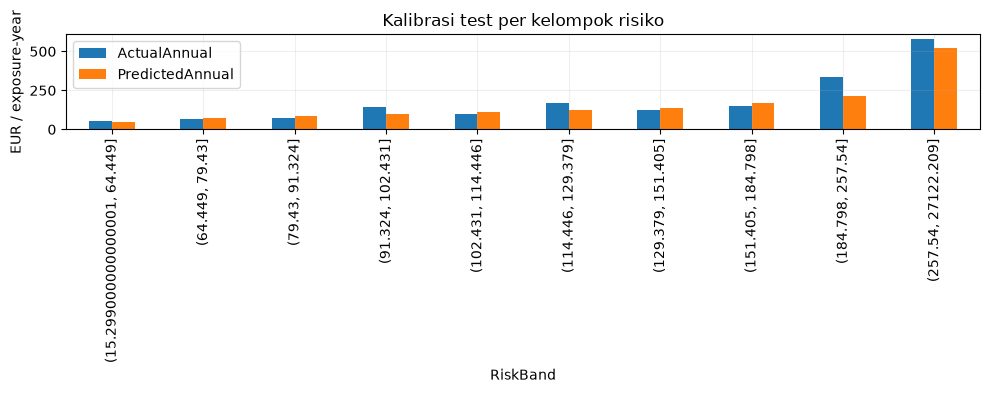

,Policies,Exposure,Actual,Predicted,ActualAnnual,PredictedAnnual,A_P
Area,,,,,,,
A,20471,12219.482611,1362692.55,1.399550e+06,111.518024,114.534302,0.973665
B,14959,8517.796512,1017562.71,1.031056e+06,119.463139,121.047299,0.986913
C,37654,20464.861048,2973995.79,2.668305e+06,145.322061,130.384726,1.114564
D,30258,15479.939966,2650641.95,2.626005e+06,171.230764,169.639204,1.009382
E,26968,12538.061126,3473318.12,2.343097e+06,277.021948,186.878719,1.482362
F,3470,1576.532757,191341.94,2.389131e+05,121.368832,151.543383,0.800885


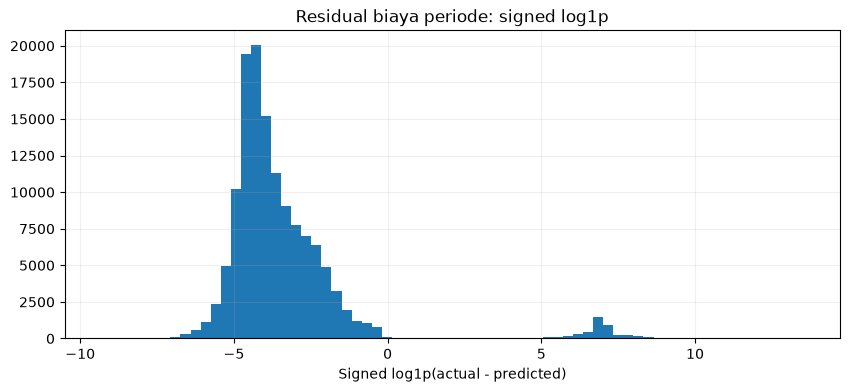

Bootstrap interval persentil 95% A/P: [0.95515775 1.31915868]


In [14]:
results['RiskBand']=pd.qcut(results.PredictedAnnualPremium,q=10,duplicates='drop') if results.PredictedAnnualPremium.nunique()>1 else 'All'
def calibration(d,col):
    t=d.groupby(col,observed=True,dropna=False).agg(Policies=('IDpol','size'),Exposure=('Exposure','sum'),Actual=('TotalClaimAmount','sum'),Predicted=('PredictedPeriodLoss','sum'))
    t['ActualAnnual']=t.Actual/t.Exposure; t['PredictedAnnual']=t.Predicted/t.Exposure
    t['A_P']=t.Actual/t.Predicted
    return t
cal=calibration(results,'RiskBand'); display(cal)
cal[['ActualAnnual','PredictedAnnual']].plot.bar(title='Kalibrasi test per kelompok risiko'); plt.ylabel('EUR / exposure-year'); plt.tight_layout(); plt.show()
display(calibration(results,'Area'))
residual=results.TotalClaimAmount-results.PredictedPeriodLoss
plt.hist(np.sign(residual)*np.log1p(np.abs(residual)),bins=70); plt.title('Residual biaya periode: signed log1p'); plt.xlabel('Signed log1p(actual - predicted)'); plt.show()
rng=np.random.default_rng(SEED); actual=results.TotalClaimAmount.to_numpy(); expected=results.PredictedPeriodLoss.to_numpy()
boot=[]
for _ in range(200):
    ix=rng.integers(0,len(results),len(results)); boot.append(actual[ix].sum()/expected[ix].sum())
print('Bootstrap interval persentil 95% A/P:',np.quantile(boot,[.025,.975]))
cal.to_csv(OUT/'calibration_test.csv')

## 11. Interpretasi: permutation importance pada validation
Model train-only dan validation digunakan agar importance tidak menjadi alasan tuning test. Setiap fitur mentah diacak dua kali; selisih deviance mengukur penurunan kualitas prediksi. Nilai negatif dapat muncul karena noise. Fitur berkorelasi dapat saling menggantikan; hasil bukan hubungan sebab-akibat. Baseline tidak memiliki importance.

,Feature,MeanIncreaseDeviance,Std
3,BonusMalus,3.104056,1.907922
2,DrivAge,0.950307,1.299693
7,VehGas,0.800509,0.085147
1,VehAge,0.542277,0.106157
0,VehPower,0.076438,0.052502
4,LogDensity,0.043475,0.359657
5,Area,-0.116637,0.050640
6,VehBrand,-0.233461,0.106661
8,Region,-0.655115,0.702488


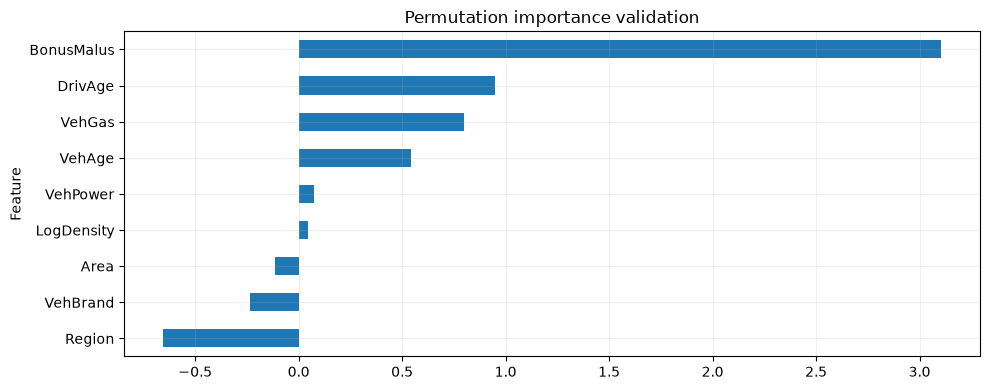

In [15]:
inspect=val.sample(min(20000,len(val)),random_state=SEED); Xi=features(inspect)
def predict_train_model(x):
    if winner=='Baseline': return np.full(len(x),base_rate)
    if winner=='FrequencySeverity': return models[freq_best].predict(x)*models[sev_best].predict(x)
    return models[direct_best].predict(x)
original=metrics(inspect,predict_train_model(Xi))['TweedieDeviance']
rng=np.random.default_rng(SEED); importance_rows=[]
for col in FEATURES:
    changes=[]
    for _ in range(2):
        xp=Xi.copy(); xp[col]=rng.permutation(xp[col].to_numpy())
        changes.append(metrics(inspect,predict_train_model(xp))['TweedieDeviance']-original)
    importance_rows.append({'Feature':col,'MeanIncreaseDeviance':np.mean(changes),'Std':np.std(changes)})
importance=pd.DataFrame(importance_rows).sort_values('MeanIncreaseDeviance',ascending=False)
display(importance)
importance.sort_values('MeanIncreaseDeviance').plot.barh(x='Feature',y='MeanIncreaseDeviance',legend=False,title='Permutation importance validation'); plt.tight_layout(); plt.show()
importance.to_csv(OUT/'permutation_importance.csv',index=False)

## 12. Contoh prediksi dan simulasi loading
Input memakai profil dari test sebagai demonstrasi; pengguna dapat mengganti nilainya. Frequency dan severity di bawah merupakan keluaran model komponen, sedangkan premi terpilih dapat berasal dari Tweedie atau baseline dan tidak harus sama dengan produknya.

Simulasi premi komersial: `(premi risiko + biaya tetap) / (1 - expense_ratio - profit_ratio)`. Rasio diasumsikan bagian dari premi bruto; angka biaya hanya asumsi ilustrasi, bukan hasil estimasi atau tarif yang disetujui. Model hanya teruji pada cohort rekonsiliasi.

In [16]:
example=test[RAW_NUM+CAT].iloc[[0]].copy()
xe=features(example)
annual=float(predict_approach(xe)[0])
fhat=float(final_models[freq_best].predict(xe)[0]); shat=float(final_models[sev_best].predict(xe)[0])
display(example)
print({'expected_claims_per_year':fhat,'expected_cost_per_claim_EUR':shat,'selected_annual_risk_premium_EUR':annual})
fixed_expense=20.; expense_ratio=.20; profit_ratio=.05
assert 0<=expense_ratio+profit_ratio<1
illustrative_gross=(annual+fixed_expense)/(1-expense_ratio-profit_ratio)
print('Premi bruto ilustratif EUR:',round(illustrative_gross,2))

,VehPower,VehAge,DrivAge,BonusMalus,Density,Area,VehBrand,VehGas,Region
647478,4.0,3.0,33.0,90.0,1001.0,D,B12,Diesel,R11


{'expected_claims_per_year': 0.07442163835119135, 'expected_cost_per_claim_EUR': 1805.4187412783044, 'selected_annual_risk_premium_EUR': 134.36222063587707}
Premi bruto ilustratif EUR: 205.82


## 13. Rekomendasi berbasis hasil dan batas penggunaan
Sel berikut menghasilkan ringkasan dari metrik aktual, bukan klaim kemenangan yang ditulis sebelum eksperimen. Jangan menyimpulkan model siap produksi hanya karena deviance lebih kecil.

In [17]:
selected=test_scores.set_index('Approach').loc[winner]
baseline=test_scores.set_index('Approach').loc['Baseline']
improvement=100*(baseline.TweedieDeviance-selected.TweedieDeviance)/baseline.TweedieDeviance
recommendations=[
    f'Pendekatan terpilih dari validation: {winner}.',
    f'Perubahan deviance test terhadap baseline: {improvement:.2f}% lebih rendah (negatif berarti lebih buruk).',
    f'Rasio actual/predicted test: {selected.Actual_over_Predicted:.3f}.',
    'Lakukan rekonsiliasi sumber untuk polis dengan severity hilang dan orphan claims sebelum membuat klaim kecukupan premi seluruh portofolio.',
    'Validasi out-of-time dan pada data pasar/cakupan yang relevan; random split saat ini tidak mengukur perubahan inflasi atau perilaku antarperiode.',
    'Pertahankan audit klaim besar; uji sensitivitas atau model large-loss terpisah dengan pemulihan biaya tail, bukan sekadar menghapus outlier.',
    'Review segmen dengan exposure kecil, stabilitas tarif, ketersediaan BonusMalus di awal periode, dan perubahan distribusi input.',
    'Monitor frekuensi, severity, A/P agregat dan per segmen; tetapkan threshold operasional bersama aktuaris berdasarkan volatilitas data.',
    'Tambahkan expense, komisi, reasuransi, biaya modal, inflasi dan margin dengan asumsi terpisah untuk pengembangan premi komersial.'
]
if selected.Actual_over_Predicted>1.1:
    recommendations.insert(3,'Aktual test >110% prediksi: investigasi underprediction dan kontribusi klaim besar; jangan mengalibrasi ulang menggunakan test ini.')
elif selected.Actual_over_Predicted<.9:
    recommendations.insert(3,'Aktual test <90% prediksi: investigasi overprediction; ambang 90%/110% hanya indikator diagnostik ilustratif.')
else:
    recommendations.insert(3,'A/P agregat dekat 1 pada sampel ini; tetap periksa ketidakpastian dan kalibrasi segmen.')
for r in recommendations: print('•',r)
(OUT/'recommendations.txt').write_text('\n'.join(recommendations),encoding='utf-8')

• Pendekatan terpilih dari validation: FrequencySeverity.
• Perubahan deviance test terhadap baseline: 7.35% lebih rendah (negatif berarti lebih buruk).
• Rasio actual/predicted test: 1.132.
• Aktual test >110% prediksi: investigasi underprediction dan kontribusi klaim besar; jangan mengalibrasi ulang menggunakan test ini.
• Lakukan rekonsiliasi sumber untuk polis dengan severity hilang dan orphan claims sebelum membuat klaim kecukupan premi seluruh portofolio.
• Validasi out-of-time dan pada data pasar/cakupan yang relevan; random split saat ini tidak mengukur perubahan inflasi atau perilaku antarperiode.
• Pertahankan audit klaim besar; uji sensitivitas atau model large-loss terpisah dengan pemulihan biaya tail, bukan sekadar menghapus outlier.
• Review segmen dengan exposure kecil, stabilitas tarif, ketersediaan BonusMalus di awal periode, dan perubahan distribusi input.
• Monitor frekuensi, severity, A/P agregat dan per segmen; tetapkan threshold operasional bersama aktuaris berdas

1135

## 14. Simpan model, konfigurasi dan uji reload
Artefak berisi pipeline preprocessing beserta estimator. `features()` harus dijalankan sebelum predict karena LogDensity dibuat di luar pipeline. Gunakan versi library yang sama saat memuat model; hanya buka joblib dari sumber tepercaya.

Paket ini mempertahankan model final dari train+validation. Tidak melakukan refit pada test agar hasil evaluasi tetap bisa direproduksi.

In [18]:
artifact={'winner':winner,'baseline_rate':final_rate,'frequency_name':freq_best,'severity_name':sev_best,'direct_name':direct_best,'models':final_models,'features':FEATURES,'versions':versions,'population':'reconciled cohort only','currency':'EUR'}
joblib.dump(artifact,OUT/'motor_pricing.joblib')
metadata={'seed':SEED,'max_policies':MAX_POLICIES,'tweedie_evaluation_power':POWER,'winner':winner,'frequency':freq_best,'severity':sev_best,'direct':direct_best,'versions':versions,'test_metrics':test_scores.to_dict(orient='records'),'scope':'French historical motor TPL; reconciled cohort; no commercial loading in model'}
(OUT/'experiment_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
loaded=joblib.load(OUT/'motor_pricing.joblib')
def predict_loaded(raw, bundle):
    x=features(raw)
    if bundle['winner']=='Baseline': return np.full(len(x),bundle['baseline_rate'])
    if bundle['winner']=='FrequencySeverity':
        return np.maximum(bundle['models'][bundle['frequency_name']].predict(x)*bundle['models'][bundle['severity_name']].predict(x),EPS)
    return np.maximum(bundle['models'][bundle['direct_name']].predict(x),EPS)
np.testing.assert_allclose(predict_loaded(example,loaded),predict_approach(xe))
print('Reload prediction verified. Output:',OUT.resolve())
print('File:',sorted(p.name for p in OUT.iterdir()))

Reload prediction verified. Output: C:\Users\Lenovo\OneDrive\Documents\Dibimbing\Data Science\Assignment\Final Project\outputs_motor_pricing
File: ['calibration_test.csv', 'experiment_metadata.json', 'model_selection_validation.csv', 'motor_pricing.joblib', 'orphan_claims.csv', 'permutation_importance.csv', 'quarantine_frequency.csv', 'quarantine_severity.csv', 'recommendations.txt', 'reconciliation_audit.csv', 'split_ids.csv', 'test_metrics.csv', 'test_predictions.csv', 'tuning_validation.csv', 'unreconciled_policies.csv']


## 15. Kesimpulan portfolio dan pengembangan berikutnya
Notebook menghasilkan estimasi premi risiko tahunan dan perbandingan model pada data yang berhasil direkonsiliasi. Gunakan tabel `test_metrics.csv` dan ringkasan otomatis untuk menulis hasil portfolio; jangan mengganti hasil dengan angka yang diharapkan.

Pengembangan: konfirmasi definisi jumlah klaim versus klaim dibayar; lengkapi nilai klaim yang hilang; repeated CV pada development untuk stabilitas seleksi; bootstrap yang mencakup refit untuk ketidakpastian model; validasi temporal; analisis inflasi dan large losses; lalu aplikasi Streamlit/FastAPI dengan validasi input dan monitoring.

### Referensi
- [CASdatasets: definisi freMTPL2](https://dutangc.github.io/CASdatasets/reference/freMTPL.html)
- [OpenML frequency 41214](https://www.openml.org/d/41214), [severity 41215](https://www.openml.org/d/41215)
- [scikit-learn: Tweedie insurance example](https://scikit-learn.org/stable/auto_examples/linear_model/plot_tweedie_regression_insurance_claims.html)
- [HistGradientBoostingRegressor: loss Poisson dan Gamma](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html)

Versi OpenML yang diunggah dapat berbeda jumlah baris dari paket CASdatasets. Notebook menggunakan file aktual dan mencatat audit; tidak memaksakan jumlah baris referensi.

In [19]:
from pathlib import Path
import json

import numpy as np
import pandas as pd


# Notebook berada di Final Project/notebook
PROJECT_ROOT = Path("..").resolve()
EDA_DIR = PROJECT_ROOT / "data" / "processed"
EDA_DIR.mkdir(parents=True, exist_ok=True)

if "train" not in globals():
    raise RuntimeError(
        "Variabel train belum tersedia. Gunakan kernel notebook "
        "yang tadi dipakai training."
    )

# 1. Ringkasan keseluruhan data train
total_exposure = float(train["Exposure"].sum())
total_claims = int(train["ClaimNb"].sum())
total_loss = float(train["TotalClaimAmount"].sum())

summary = {
    "population": "Train — polis yang lolos rekonsiliasi",
    "policies": int(len(train)),
    "exposure_years": total_exposure,
    "claims": total_claims,
    "total_loss_eur": total_loss,
    "frequency": total_claims / total_exposure,
    "severity_eur": (
        total_loss / total_claims if total_claims > 0 else None
    ),
    "pure_premium_eur": total_loss / total_exposure,
    "zero_claim_pct": float(
        100 * train["ClaimNb"].eq(0).mean()
    ),
}

(EDA_DIR / "eda_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False),
    encoding="utf-8",
)

# 2. Distribusi jumlah klaim per polis
claim_distribution = (
    train["ClaimNb"]
    .value_counts()
    .sort_index()
    .rename_axis("ClaimNb")
    .reset_index(name="Policies")
)

claim_distribution.to_csv(
    EDA_DIR / "eda_claim_distribution.csv",
    index=False,
)

# 3. Pengalaman klaim per segmen
eda = train.copy()

eda["DriverAgeBand"] = pd.cut(
    eda["DrivAge"],
    bins=[17, 25, 35, 45, 55, 65, np.inf],
    labels=["18–25", "26–35", "36–45", "46–55", "56–65", "66+"],
)

segment_tables = []

for column in ["DriverAgeBand", "Area", "VehGas", "Region"]:
    table = (
        eda.groupby(column, observed=True, dropna=False)
        .agg(
            Policies=("IDpol", "size"),
            Exposure=("Exposure", "sum"),
            Claims=("ClaimNb", "sum"),
            Loss=("TotalClaimAmount", "sum"),
        )
        .reset_index()
    )

    table["Frequency"] = table["Claims"] / table["Exposure"]
    table["Severity"] = (
        table["Loss"] / table["Claims"].replace(0, np.nan)
    )
    table["PurePremium"] = table["Loss"] / table["Exposure"]

    table = table.rename(columns={column: "Segment"})
    table["Segment"] = (
        table["Segment"].astype("string").fillna("Tidak tersedia")
    )
    table.insert(0, "Dimension", column)

    segment_tables.append(table)

pd.concat(segment_tables, ignore_index=True).to_csv(
    EDA_DIR / "eda_segments.csv",
    index=False,
)

# 4. Histogram — simpan jumlah polis pada setiap interval
histogram_tables = []

histogram_inputs = {
    "DrivAge": train["DrivAge"],
    "Exposure": train["Exposure"],
    "Log10AvgSeverity": np.log10(
        train.loc[train["AvgSeverity"].gt(0), "AvgSeverity"]
    ),
}

for name, values in histogram_inputs.items():
    values = values.replace([np.inf, -np.inf], np.nan).dropna()

    counts, edges = np.histogram(values, bins=40)

    histogram_tables.append(pd.DataFrame({
        "Variable": name,
        "Left": edges[:-1],
        "Right": edges[1:],
        "Count": counts,
    }))

pd.concat(histogram_tables, ignore_index=True).to_csv(
    EDA_DIR / "eda_histograms.csv",
    index=False,
)

print("Ringkasan EDA berhasil disimpan:")
for file in sorted(EDA_DIR.glob("eda_*")):
    print(f"{file.name} → {file.stat().st_size:,} bytes")

Ringkasan EDA berhasil disimpan:
eda_claim_distribution.csv → 71 bytes
eda_histograms.csv → 5,795 bytes
eda_segments.csv → 4,012 bytes
eda_summary.json → 348 bytes
